# Decision tree search
Predict restaurant ratings from business attributes. **Select by MAE (lower is better); also report R² (higher is better).**

R² compares squared error with predicting the validation-fold mean: 1 is perfect, 0 matches that benchmark, and negative is worse. Scores below are means across five folds, not pooled R² or classification accuracy.

Same development rows, preprocessing, and five folds as notebook 02. Saved outputs are viewable on GitHub; to rerun, install `requirements-modeling.txt` and run notebook 01 first to create the local data. AI-assisted extraction and feature-removal experiments.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import KFold, GridSearchCV, cross_validate
from sklearn.metrics import mean_absolute_error, r2_score
from threadpoolctl import threadpool_limits

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data/02_processed/restaurants_development.csv").exists()), None)
assert ROOT is not None, "Run notebook 01 first to create the processed data."
spec = json.loads((ROOT / "reports/eda/feature_spec.json").read_text())
NUM, CAT = spec["numeric_candidates"], spec["categorical_candidates"]
dev = pd.read_csv(ROOT / "data/02_processed/restaurants_development.csv",
                  dtype={c: str for c in CAT})
dev[CAT] = dev[CAT].astype(object).where(dev[CAT].notna(), np.nan)
assert dev.business_id.is_unique and dev["split"].eq("development").all()
assert dev.stars.notna().all() and dev.stars.between(1, 5).all()
X, y = dev[NUM + CAT], dev.stars.to_numpy()
SEED = 6021
folds = list(KFold(n_splits=5, shuffle=True, random_state=SEED).split(X))
BLUE, ORANGE = "#276A86", "#B56A3D"
plt.rcParams.update({"figure.dpi": 120, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
print(f"{len(dev):,} restaurants | {len(NUM + CAT)} features | 5 folds | sklearn {sklearn.__version__}")

41,802 restaurants | 15 features | 5 folds | sklearn 1.2.1


In [2]:
def tree_pipeline(numeric, categorical):
    # Each training fold learns its own imputation and encoding.
    blocks = []
    if numeric:
        blocks += [
            ("numeric", Pipeline([("impute", SimpleImputer(strategy="median")),
                                   ("scale", StandardScaler())]), numeric),
            ("missing", MissingIndicator(features="all"), numeric),
        ]
    if categorical:
        blocks.append(("categorical", Pipeline([
            ("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
            ("encode", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                     min_frequency=50, sparse_output=False)),
        ]), categorical))
    return Pipeline([
        ("prepare", ColumnTransformer(blocks, sparse_threshold=0)),
        ("tree", DecisionTreeRegressor(min_samples_leaf=50, random_state=SEED)),
    ])


def neg_mae(model, inputs, actual):
    return -mean_absolute_error(actual, np.clip(model.predict(inputs), 1, 5))

def r2_clipped(model, inputs, actual):
    return r2_score(actual, np.clip(model.predict(inputs), 1, 5))

scoring = {"mae": neg_mae, "r2": r2_clipped}

## 1. Grid search
Original grid: **max depth = 4, 8, 12**; minimum leaf size = **50**. Select the lowest mean validation MAE.

In [3]:
search = GridSearchCV(
    tree_pipeline(NUM, CAT), {"tree__max_depth": [4, 8, 12]},
    scoring=scoring, cv=folds, return_train_score=True, refit=False, n_jobs=1,
    error_score="raise",
)
with threadpool_limits(limits=2):
    search.fit(X, y)

cv = pd.DataFrame(search.cv_results_)
depths = cv["param_tree__max_depth"].astype(int).to_numpy()
validation = -cv["mean_test_mae"].to_numpy()
training = -cv["mean_train_mae"].to_numpy()
fold_mae = -cv[[f"split{k}_test_mae" for k in range(5)]].to_numpy()
fold_r2 = cv[[f"split{k}_test_r2" for k in range(5)]].to_numpy()
fold_sd = fold_mae.std(axis=1, ddof=1)
# R² is reported; MAE still selects the configuration.
best = int(np.argmin(validation))
best_params = cv.loc[best, "params"]
best_depth = best_params["tree__max_depth"]
full_scores, full_r2 = fold_mae[best], fold_r2[best]
print(f"Selected depth: {best_depth} | minimum leaf size: 50")
display(pd.DataFrame({"Max depth": depths, "CV MAE": validation,
                      "CV R²": fold_r2.mean(axis=1)}).round(4).set_index("Max depth"))

Selected depth: 12 | minimum leaf size: 50


,CV MAE,CV R²
Max depth,,
4,0.5822,0.2068
8,0.5648,0.2602
12,0.5614,0.2627


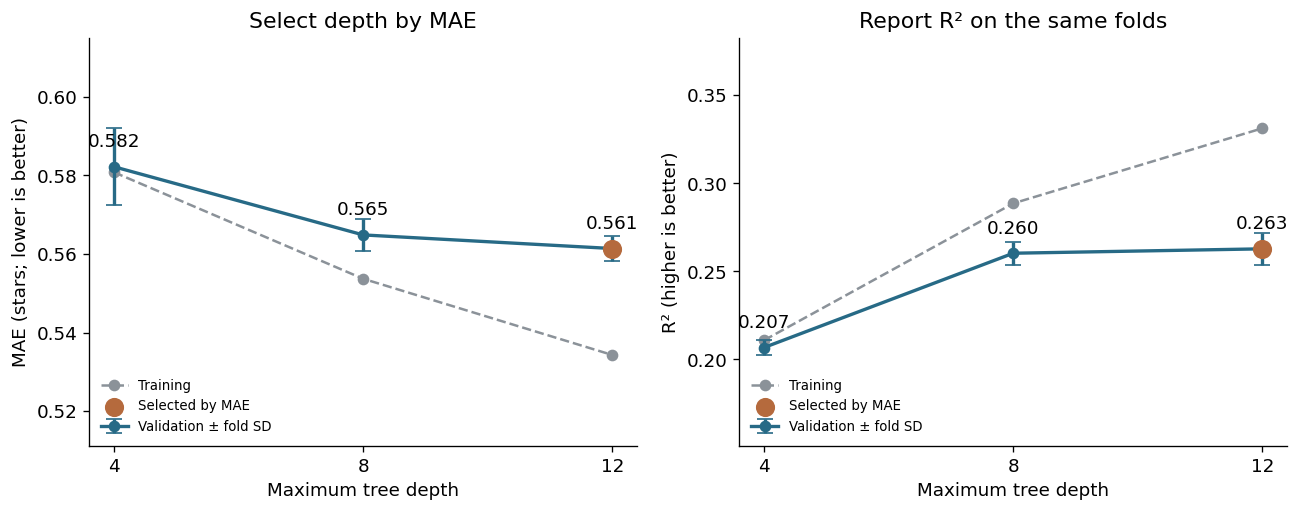

**Takeaway:** Depth **12** wins by validation MAE (**0.561 stars**); its mean validation R² is **0.263**. Error bars show fold SD, not confidence intervals.

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
plot_metrics = [
    (training, validation, fold_sd, "MAE (stars; lower is better)", "Select depth by MAE"),
    (cv["mean_train_r2"].to_numpy(), fold_r2.mean(axis=1), fold_r2.std(axis=1, ddof=1),
     "R² (higher is better)", "Report R² on the same folds"),
]
for ax, (train_mean, valid_mean, sd, ylabel, title) in zip(axes, plot_metrics):
    ax.plot(depths, train_mean, "o--", color="#8B9299", label="Training")
    ax.errorbar(depths, valid_mean, yerr=sd, fmt="o-", color=BLUE,
                capsize=5, linewidth=2, label="Validation ± fold SD")
    ax.scatter([best_depth], [valid_mean[best]], s=110, color=ORANGE,
               zorder=5, label="Selected by MAE")
    for depth, score in zip(depths, valid_mean):
        ax.annotate(f"{score:.3f}", (depth, score), xytext=(0, 12),
                    textcoords="offset points", ha="center")
    ax.set(xticks=depths, xlabel="Maximum tree depth", ylabel=ylabel, title=title)
    ax.margins(y=.4)
    ax.legend(frameon=False, fontsize=8, loc="lower left")
fig.tight_layout()
plt.show()
plt.close(fig)
display(Markdown(f"**Takeaway:** Depth **{best_depth}** wins by validation MAE "
                 f"(**{validation[best]:.3f} stars**); its mean validation R² is "
                 f"**{full_r2.mean():.3f}**. Error bars show fold SD, not confidence intervals."))

## 2. Feature ablations
New comparisons added to the original search: remove one feature group, refit, and compare on the **same folds**. Keep the selected depth and leaf size fixed; removing numeric inputs also removes their missingness indicators.

Geography = latitude, longitude, state, city/state. Numeric = geography coordinates, category count, listed days, weekly hours. Categorical = location labels, price tier, and restaurant attributes.

In [5]:
geography = {"latitude", "longitude", "state", "city_state"}
variants = {
    "Remove geography": ([c for c in NUM if c not in geography],
                         [c for c in CAT if c not in geography]),
    "Remove numeric inputs": ([], CAT),
    "Remove categorical inputs": (NUM, []),
}
scores = {"All features": full_scores}
r2_scores = {"All features": full_r2}
with threadpool_limits(limits=2):
    for label, (numeric, categorical) in variants.items():
        model = tree_pipeline(numeric, categorical).set_params(**best_params)
        result = cross_validate(model, X, y, cv=folds, scoring=scoring, n_jobs=1,
                                error_score="raise")
        scores[label] = -result["test_mae"]
        r2_scores[label] = result["test_r2"]

scores = pd.DataFrame(scores, index=range(1, 6))
scores.index.name = "fold"
means = scores.mean()
deltas = scores.drop(columns="All features").sub(scores["All features"], axis=0)
assert scores.shape == (5, 4) and np.isfinite(scores.to_numpy()).all()
r2_scores = pd.DataFrame(r2_scores, index=scores.index)
r2_means = r2_scores.mean()
assert r2_scores.shape == (5, 4) and np.isfinite(r2_scores.to_numpy()).all()
display(pd.DataFrame({"CV MAE": means, "CV R²": r2_means,
                      "Δ MAE": means - means["All features"],
                      "Δ R²": r2_means - r2_means["All features"]}).round(4))

,CV MAE,CV R²,Δ MAE,Δ R²
All features,0.5614,0.2627,0.0000,0.0000
Remove geography,0.5583,0.2714,-0.0031,0.0087
Remove numeric inputs,0.5996,0.1749,0.0383,-0.0878
Remove categorical inputs,0.5943,0.1859,0.0330,-0.0769


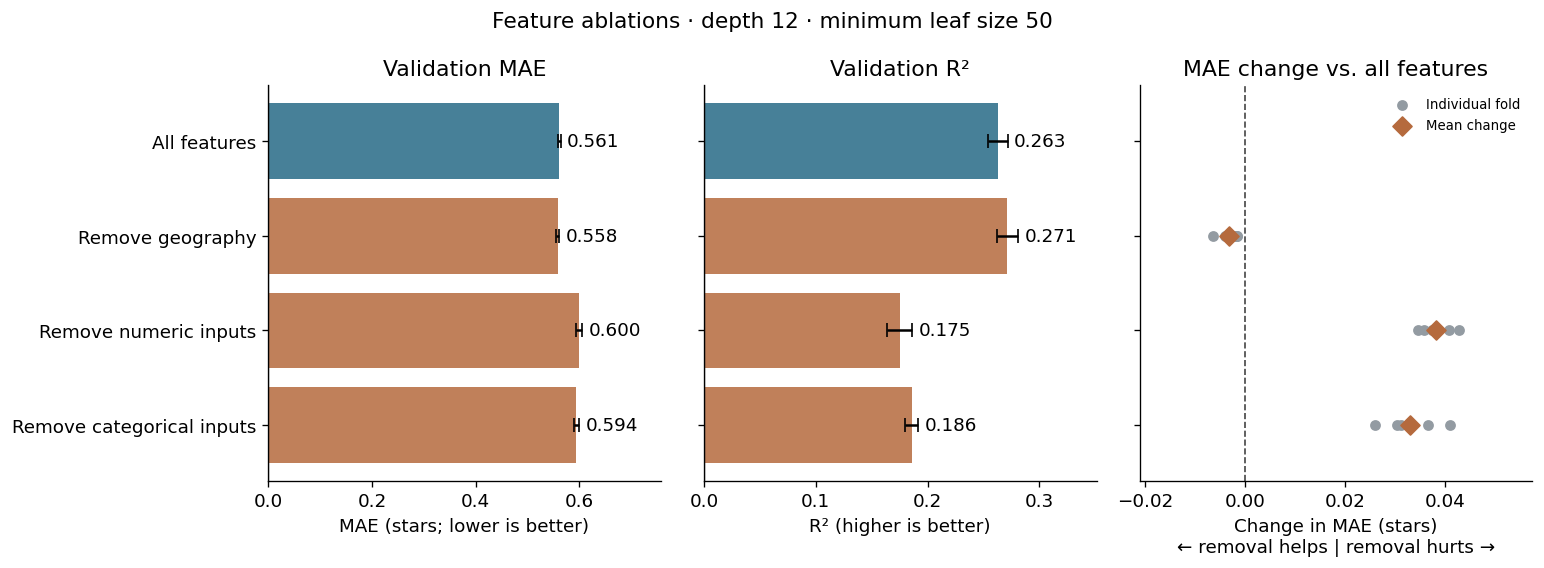

**Takeaway:** The largest mean MAE change is **+0.038 stars** for **remove numeric inputs**, with R² changing by **-0.088**. These fixed-setting development comparisons are exploratory; they do not measure causal effects or final test performance.

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.8), sharey=True)
positions = np.arange(len(means))
colors = [BLUE, ORANGE, ORANGE, ORANGE]
for ax, values, sd, xlabel, title in [
    (axes[0], means, scores.std(), "MAE (stars; lower is better)", "Validation MAE"),
    (axes[1], r2_means, r2_scores.std(), "R² (higher is better)", "Validation R²"),
]:
    ax.barh(positions, values, color=colors, alpha=.85, xerr=sd, capsize=4)
    lower = min(0, (values - sd).min())
    upper = max(0, (values + sd).max())
    span = max(upper - lower, .01)
    for i, value in enumerate(values):
        ax.text(value + sd.iloc[i] + .02 * span, i, f"{value:.3f}", va="center")
    ax.set(xlim=(lower - (.05 * span if lower < 0 else 0), upper + .25 * span),
           xlabel=xlabel, title=title)
    ax.axvline(0, color="#444444", linewidth=.8)
axes[0].set(yticks=positions, yticklabels=means.index)
axes[0].invert_yaxis()

for i, label in enumerate(deltas.columns, start=1):
    axes[2].scatter(deltas[label], np.full(5, i), color="#939BA2", s=30,
                    label="Individual fold" if i == 1 else None)
axes[2].scatter(deltas.mean(), range(1, 4), color=ORANGE, marker="D", s=65,
                zorder=3, label="Mean change")
axes[2].axvline(0, color="#444444", linestyle="--", linewidth=1)
axes[2].set(xlabel="Change in MAE (stars)\n← removal helps | removal hurts →",
            title="MAE change vs. all features")
axes[2].margins(x=.3)
axes[2].legend(frameon=False, fontsize=8, loc="upper right")
fig.suptitle(f"Feature ablations · depth {best_depth} · minimum leaf size 50", fontsize=13)
fig.tight_layout()
plt.show()
plt.close(fig)

largest = deltas.mean().idxmax()
change = deltas.mean()[largest]
r2_change = r2_means[largest] - r2_means["All features"]
display(Markdown(f"**Takeaway:** The largest mean MAE change is **{change:+.3f} stars** "
                 f"for **{largest.lower()}**, with R² changing by **{r2_change:+.3f}**. "
                 "These fixed-setting development comparisons are exploratory; "
                 "they do not measure causal effects or final test performance."))

Only development data is used here. The test set was previously evaluated in notebook 02; these selection/ablation scores are exploratory. Source: [02_restaurant_ratings_modeling.ipynb](02_restaurant_ratings_modeling.ipynb).